# 06 · Robustness: missing amounts, projects, and alternative definitions (v1.5)

The main analysis uses the 802 grants that Dimensions lists with an amount. This notebook asks whether the
headline results depend on that choice or on other definitions.

| Output | Content |
|---|---|
| Figure S12, Table S30 | Screening flow, from the raw Dimensions export |
| Table S31 | Award types of grants with and without an amount |
| Table S32 | Count-based shares: grants with an amount, without one, and all relevant grants |
| Table S33 | Dollar shares when missing amounts are recovered or imputed |
| Table S34 | Yearly records merged into projects |
| Table S35 | Gender gap: subsets that test name-based inference and award type |
| Table S36 | Topic shares from topic probabilities instead of one topic per grant |
| Figure S13, Table S37 | Robustness summary: every headline under every check |

It also writes private worksheets (never committed) for the steps that need people: recovering amounts from
funder websites and double-checking screening, topics and inferred gender. When those files are filled in and
saved under `data/raw/`, rerunning this notebook uses them.

Run after `05_concentration_and_sensitivity` and `02_topic_modelling` (it reads `topic_probabilities_rerun.csv`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import phagefund as pf
import figures as fg
import robustness as rb

RAW, INTERIM, REF = ROOT / "data" / "raw", ROOT / "data" / "interim", ROOT / "data" / "reference"
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
EXPORT = RAW / "dimensions_export_2024-02-13.xlsx"
fg.use_style()

d = pf.load(ROOT / "data" / "processed" / "phage_funding_analysis.csv")
d["award_type"] = [rb.award_type(p, l) for p, l in zip(d["Program"], d["Source Linkout"])]
u = rb.load_unpriced(EXPORT)
ref = pd.read_csv(REF / "country_classification.csv").set_index("country")
KN = TAB / "key_numbers.json"
key = json.loads(KN.read_text())
TOTAL = d[pf.USD].sum()
print(f"{len(d)} grants with an amount (USD {TOTAL/1e6:.1f}M); {len(u)} relevant grants without an amount, 1999-2023")

802 grants with an amount (USD 318.6M); 272 relevant grants without an amount, 1999-2023


## 1. Screening flow (Figure S12, Table S30)

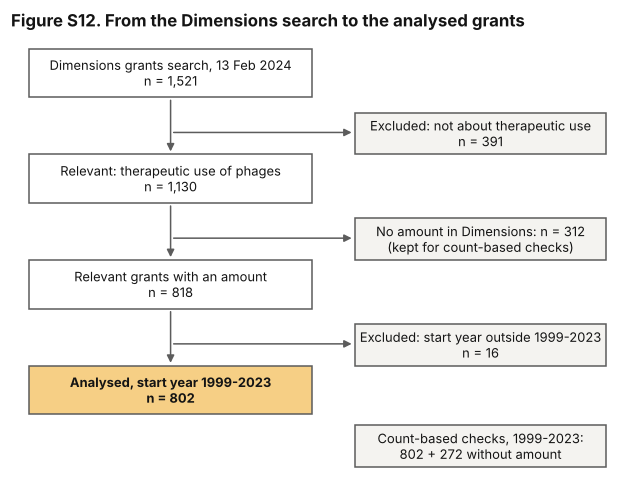

,Step,Records,Note
0,Records exported from Dimensions (13 Feb 2024),1521,
1,Excluded: not about therapeutic use of phages,391,"386 coded 0, 5 coded -1"
2,Relevant grants,1130,
3,Excluded from dollar analyses: no amount in Di...,312,kept for count-based checks
4,Grants with an amount,818,
5,Excluded: start year outside 1999-2023,16,
6,Analysed (dollar analyses),802,
7,"Relevant grants without an amount, 1999-2023 (...",272,


In [2]:
flow = rb.screening_flow(EXPORT, d)
flow.to_csv(TAB / "S30_screening_flow.csv", index=False)
n = dict(zip(flow.Step, flow.Records))

fig, ax = plt.subplots(figsize=(7.2, 5.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10)
def box(x, y, w, h, text, fc="white", ec=pf.INK2, bold=False):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec=ec, lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8.5, color=pf.INK,
            fontweight="bold" if bold else "normal", wrap=True)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=pf.INK2, lw=1))
L, W, H = 0.3, 4.6, 1.1
box(L, 8.6, W, H, f"Dimensions grants search, 13 Feb 2024\nn = {n['Records exported from Dimensions (13 Feb 2024)']:,}")
box(L, 6.2, W, H, f"Relevant: therapeutic use of phages\nn = {n['Relevant grants']:,}")
box(L, 3.8, W, H, f"Relevant grants with an amount\nn = {n['Grants with an amount']:,}")
box(L, 1.4, W, H, f"Analysed, start year 1999-2023\nn = {n['Analysed (dollar analyses)']:,}", fc=fg.SEQ[1], bold=True)
for y in (8.6, 6.2, 3.8):
    arrow(L + W / 2, y, L + W / 2, y - 1.3)
R = 5.6
box(R, 7.3, 4.1, 0.95, f"Excluded: not about therapeutic use\nn = {n['Excluded: not about therapeutic use of phages']:,}", fc="#f4f3f0")
box(R, 4.9, 4.1, 0.95, f"No amount in Dimensions: n = {n['Excluded from dollar analyses: no amount in Dimensions']:,}\n(kept for count-based checks)", fc="#f4f3f0")
box(R, 2.5, 4.1, 0.95, f"Excluded: start year outside 1999-2023\nn = {n['Excluded: start year outside 1999-2023']:,}", fc="#f4f3f0")
box(R, 0.2, 4.1, 0.95, f"Count-based checks, 1999-2023:\n{n['Analysed (dollar analyses)']:,} + {n['Relevant grants without an amount, 1999-2023 (count-based checks)']:,} without amount", fc="#f4f3f0")
for y in (7.75, 5.35, 2.95):
    arrow(L + W / 2, y + 0.05, R, y + 0.05)
ax.set_title("Figure S12. From the Dimensions search to the analysed grants", loc="left")
fg.save(fig, FIG, "FigS12_screening_flow"); plt.show()
flow

## 2. What the grants without an amount are (Table S31)

Many records without an amount are not missing money: studentships, scholarships, theses and graduate-programme
records usually carry no grant value in Dimensions. `robustness.award_type` sorts every record into research
grants, training awards and capacity (formula) funding from the programme name and source link.

In [3]:
s31 = pd.DataFrame({
    "With an amount (n)": d["award_type"].value_counts(),
    "Without an amount (n)": u["award_type"].value_counts(),
}).fillna(0).astype(int).reindex(["Research grant", "Training award", "Capacity funding"])
s31.loc["Total"] = s31.sum()
for c in ["With an amount (n)", "Without an amount (n)"]:
    s31[c.replace("(n)", "(%)")] = (s31[c] / s31.loc["Total", c] * 100).round(1)
s31.index.name = "Award type"
s31.to_csv(TAB / "S31_award_types.csv")
display(s31)
top_unpriced = (u.groupby([pf.FUNDER, "Funder Country"]).size().sort_values(ascending=False).head(10)
                .rename("Grants without an amount").reset_index())
top_unpriced

,With an amount (n),Without an amount (n),With an amount (%),Without an amount (%)
Award type,,,,
Research grant,717,136,89.4,50.0
Training award,61,117,7.6,43.0
Capacity funding,24,19,3.0,7.0
Total,802,272,100.0,100.0


,Funder,Funder Country,Grants without an amount
0,São Paulo Research Foundation,Brazil,56
1,Coordenação de Aperfeicoamento de Pessoal de N...,Brazil,23
2,Russian Foundation for Basic Research,Russia,23
3,Biotechnology and Biological Sciences Research...,United Kingdom,17
4,Belgian Federal Science Policy Office,Belgium,16
5,National Institute of Food and Agriculture,United States,16
6,Research Foundation - Flanders,Belgium,15
7,National Research Foundation,South Africa,14
8,Russian Science Foundation,Russia,12
9,Medical Research Council,United Kingdom,9


## 3. Count-based shares (Table S32)

Each grant counts once, split equally across its recipient countries. The 802 grants use the cleaned
recipient lists of the main analysis; the 272 grants use the countries in the Dimensions export (cleaned for
spelling). "No country": the record lists no recipient country.

In [4]:
def count_shares(priced, unpriced):
    rows = pd.concat([rb.long_recipients(priced), rb.long_recipients(unpriced)], ignore_index=True)
    s = rb.recipient_shares(rows, ref)
    fc = pd.concat([priced["Funder Country"], unpriced["Funder Country"]])
    out = {
        "Grants": len(priced) + len(unpriced),
        "Recipients in the Global South (%)": s.get("North/South: Global South", 0),
        "Recipients in low or lower-middle income countries (%)":
            s.get("Income group: Lower middle income", 0) + s.get("Income group: Low income", 0),
        "Recipients with no country (%)": s.get("North/South: No country", 0),
        "Recipients in the United States (%)": rows.loc[rows.country == "United States", "w"].sum() / rows.w.sum() * 100,
        "Recipients in Brazil (%)": rows.loc[rows.country == "Brazil", "w"].sum() / rows.w.sum() * 100,
        "Funders in the Global South (%)": fc.map(ref["north_south"]).eq("Global South").mean() * 100,
        "Funders in the United States (%)": fc.eq("United States").mean() * 100,
    }
    yrs = pd.concat([priced[pf.YEAR], unpriced[pf.YEAR]]).astype(int).value_counts().reindex(range(1999, 2024), fill_value=0)
    out["Growth in grants per year, 1999-2022 (%)"] = pf.loglinear_growth(yrs)["annual_growth_pct"]
    return pd.Series(out)

empty = u.iloc[0:0]
research = lambda x: x[x["award_type"] != "Training award"]
s32 = pd.DataFrame({
    "With an amount": count_shares(d, empty),
    "Without an amount": count_shares(d.iloc[0:0], u),
    "All relevant grants": count_shares(d, u),
    "All, without training awards": count_shares(research(d), research(u)),
}).round(1)
s32.index.name = "Measure (share of grants)"
s32.to_csv(TAB / "S32_count_based_shares.csv")
s32

/home/claude/phage-therapy-funding-v1/src/phagefund.py:79: RuntimeWarning: divide by zero encountered in log
  coef, cov = np.polyfit(t, np.log(s.values), 1, cov=True)


,With an amount,Without an amount,All relevant grants,"All, without training awards"
Measure (share of grants),,,,
Grants,802.0,272.0,1074.0,896.0
Recipients in the Global South (%),11.8,34.4,17.5,14.1
Recipients in low or lower-middle income countries (%),1.4,1.7,1.4,1.7
Recipients with no country (%),0.0,17.3,4.4,3.8
Recipients in the United States (%),31.4,11.2,26.3,29.6
Recipients in Brazil (%),0.0,28.7,7.3,2.4
Funders in the Global South (%),11.3,39.0,18.3,14.3
Funders in the United States (%),31.9,12.1,26.9,30.2
"Growth in grants per year, 1999-2022 (%)",12.2,NaN,13.1,13.0


## 4. Dollar shares with recovered or imputed amounts (Table S33)

**Recovered**: amounts found by hand on funder websites, from `data/raw/recovered_amounts.csv` (the filled-in
worksheet of section 5); used when present. **Imputed**: each missing amount is replaced by the median (or 25th/75th
percentile) of priced grants from the same funder (at least 3), else the same funder country and award type, else
the same award type. Training awards are set to 0 in the central and low scenarios (most are stipends without a grant
value) and to the 25th percentile of priced training awards in the high scenario.

In [5]:
recovered = rb.read_recovered(RAW / "recovered_amounts.csv")
print(f"Recovered amounts available: {len(recovered)} of {len(u)}")

def scenario(fill):
    """fill: Series of USD for the unpriced grants (NaN = leave out)."""
    uu = u.assign(**{pf.USD: fill}).dropna(subset=[pf.USD])
    allg = pd.concat([d.assign(src="priced"), uu.assign(src="unpriced")], ignore_index=True)
    tot = allg[pf.USD].sum()
    rows = pd.concat([rb.long_recipients(d, pf.USD), rb.long_recipients(uu, pf.USD)], ignore_index=True)
    s = rb.recipient_shares(rows, ref)
    yr = allg.groupby(pf.YEAR)[pf.USD].sum().reindex(range(1999, 2024), fill_value=0)
    fc = allg.groupby("Funder Country")[pf.USD].sum()
    return pd.Series({
        "Grants with an amount": len(allg),
        "Total (USD M)": tot / 1e6,
        "Recipients in the Global South (%)": s.get("North/South: Global South", 0),
        "Recipients in low or lower-middle income countries (%)":
            s.get("Income group: Lower middle income", 0) + s.get("Income group: Low income", 0),
        "Recipients in Brazil (%)": rows.loc[rows.country == "Brazil", "w"].sum() / tot * 100,
        "Funding from US funders (%)": fc.get("United States", 0) / tot * 100,
        "Funding from NIAID (%)": allg.loc[allg[pf.FUNDER] == pf.NIAID, pf.USD].sum() / tot * 100,
        "Funder-country HHI": pf.hhi(fc),
        "Funding growth 1999-2022 (%/yr)": pf.loglinear_growth(yr)["annual_growth_pct"],
    })

q = lambda qq, tz=True: rb.impute_amounts(d, u, q=qq, training_zero=tz)
high = q(0.75).where(u["award_type"] != "Training award", q(0.25, tz=False))
cols = {"Recorded amounts only (main analysis)": scenario(pd.Series(np.nan, index=u.index))}
if len(recovered):
    cols["Recorded + recovered amounts"] = scenario(u["Grant ID"].map(recovered))
cols.update({
    "Imputed, low (25th percentile)": scenario(q(0.25)),
    "Imputed, central (median)": scenario(q(0.5)),
    "Imputed, high (75th percentile)": scenario(high),
})
s33 = pd.DataFrame(cols).round(2)
s33.index.name = "Measure"
s33.to_csv(TAB / "S33_imputed_amount_scenarios.csv")
s33

Recovered amounts available: 0 of 272


,Recorded amounts only (main analysis),"Imputed, low (25th percentile)","Imputed, central (median)","Imputed, high (75th percentile)"
Measure,,,,
Grants with an amount,802.00,1074.00,1074.00,1074.00
Total (USD M),318.63,331.82,353.78,400.15
Recipients in the Global South (%),2.11,2.64,3.80,5.49
Recipients in low or lower-middle income countries (%),0.33,0.55,0.54,0.52
Recipients in Brazil (%),0.05,0.32,1.23,2.64
Funding from US funders (%),47.65,47.40,45.11,41.39
Funding from NIAID (%),20.98,20.15,18.90,16.71
Funder-country HHI,2501.00,2466.00,2245.00,1953.00
Funding growth 1999-2022 (%/yr),16.60,16.30,16.00,16.10


## 5. Worksheet for recovering amounts (private)

One row per grant without an amount, research grants first, with the funder's own page. Fill `recovered_amount`,
`currency` and `recovered_usd` (USD at the start-year average rate), add a note on the source, and save the file as
`data/raw/recovered_amounts.csv`. Grant-level, so it stays out of the repository.

In [6]:
order = {"Research grant": 0, "Capacity funding": 1, "Training award": 2}
ws = (u.assign(_o=u["award_type"].map(order))
       .sort_values(["_o", pf.FUNDER, pf.YEAR])
       [["Grant ID", "Grant Number(s)", pf.FUNDER, "Funder Country", pf.YEAR, "award_type", "Program", "Source Linkout", "Dimensions URL"]]
       .assign(recovered_amount="", currency="", recovered_usd="", source_note=""))
ws.to_csv(INTERIM / "amount_recovery_worksheet.csv", index=False)
ws.to_excel(INTERIM / "amount_recovery_worksheet.xlsx", index=False)
print(f"{len(ws)} rows written to data/interim/ (private).")
ws["Source Linkout"].astype(str).str.extract(r"https?://([^/]+)")[0].value_counts().head(12).rename("Rows by funder website")

272 rows written to data/interim/ (private).


0
bv.fapesp.br             56
gtr.ukri.org             29
portal.nifa.usda.gov     26
sucupira.capes.gov.br    23
www.rfbr.ru              14
www.rscf.ru              12
www.netd.ac.za           10
gepris.dfg.de             8
mygrants.gov.my           6
fulbrightscholars.org     5
admin.frs-fnrs.be         4
projectdb.jst.go.jp       4
Name: Rows by funder website, dtype: int64

## 6. Yearly records merged into projects (Table S34)

Some funders list each year of a project as its own record (for example NSERC). `robustness.to_projects` merges
records with the same funder and the same English title whose years follow on. Counts of grants and the
engagement labels are then recomputed per project.

In [7]:
proj = rb.to_projects(d)
merged = proj[proj.records > 1]
def eng_share(frame, label, span=False):
    lab = pf.classify_engagement(frame, span=span)
    return (lab == label).mean() * 100
pc = proj[pf.YEAR].astype(int).value_counts().reindex(range(1999, 2024), fill_value=0)
gc = d[pf.YEAR].astype(int).value_counts().reindex(range(1999, 2024), fill_value=0)
s34 = pd.DataFrame({
    "Grant records": {
        "Units": len(d), "Units built from more than one record": 0,
        "Growth in units per year, 1999-2022 (%)": pf.loglinear_growth(gc)["annual_growth_pct"],
        "Transient researchers, start-year rule (%)": eng_share(d, "Transient"),
        "Transient researchers, full-span rule (%)": eng_share(d, "Transient", span=True),
    },
    "Projects": {
        "Units": len(proj), "Units built from more than one record": len(merged),
        "Growth in units per year, 1999-2022 (%)": pf.loglinear_growth(pc)["annual_growth_pct"],
        "Transient researchers, start-year rule (%)": eng_share(proj, "Transient"),
        "Transient researchers, full-span rule (%)": eng_share(proj, "Transient", span=True),
    },
}).round(1)
s34.index.name = "Measure"
s34.to_csv(TAB / "S34_projects.csv")
display(s34)
merged.groupby(pf.FUNDER)["records"].agg(projects="size", records="sum").sort_values("records", ascending=False).head(8)

,Grant records,Projects
Measure,,
Units,802.0,771.0
Units built from more than one record,0.0,25.0
"Growth in units per year, 1999-2022 (%)",12.2,12.3
"Transient researchers, start-year rule (%)",82.1,82.9
"Transient researchers, full-span rule (%)",3.5,3.5


,projects,records
Funder,,
Natural Sciences and Engineering Research Council,9,21
National Institute of Allergy and Infectious Diseases,6,15
Congressionally Directed Medical Research Programs,2,4
Biotechnology and Biological Sciences Research Council,1,2
Academy of Finland,1,2
Danish Ministry of Higher Education and Science,1,2
Directorate for Biological Sciences,1,2
Fonds de Recherche du Québec - Santé,1,2


## 7. Gender gap: subsets (Table S35)

Main model of Table S3 (team size, grant length, start year, funder, topic). Name-based gender inference is less
reliable for Japanese and Chinese names, so one row drops grants from funders in Japan and China. Another drops
training awards, which have fixed stipends.

In [8]:
main = {k: v for k, v in pf.GENDER_MODELS.items() if k.startswith("Main")}
def fem(frame, label):
    t = pf.gender_tests(frame, models=main)
    r = t.loc["Female only vs Male only"]
    return {"Subset": label, "Grants in model": int(r["N"]), "Female-only vs male-only (%)": r["Adjusted difference (%)"],
            "95% CI low (%)": r["95% CI low (%)"], "95% CI high (%)": r["95% CI high (%)"], "p": r["Regression p"]}
s35 = pd.DataFrame([
    fem(d, "All grants (main result)"),
    fem(d[~d["Funder Country"].isin(["Japan", "China"])], "Without funders in Japan and China"),
    fem(d[d["award_type"] != "Training award"], "Without training awards"),
]).set_index("Subset").round(3)
s35.to_csv(TAB / "S35_gender_subsets.csv")
s35

,Grants in model,Female-only vs male-only (%),95% CI low (%),95% CI high (%),p
Subset,,,,,
All grants (main result),742,-18.731,-32.289,-2.458,0.026
Without funders in Japan and China,549,-20.864,-36.580,-1.253,0.038
Without training awards,686,-20.224,-34.176,-3.315,0.021


## 8. Topic shares from probabilities (Table S36)

The main analysis gives each grant one topic (the frozen 2024 assignment). Here each grant's amount is split across
topics by the probabilities of the refitted model (notebook 02, relabelled to the 2024 topic numbers). The refit agrees
with the 2024 assignment for 59% of grants, so the table also shows the refit's own one-topic shares: the difference
between columns 1 and 2 is the refit, between 2 and 3 the splitting.

In [9]:
probs = pd.read_csv(INTERIM / "topic_probabilities_rerun.csv").set_index("Grant ID")
from preprocess import TOPIC_NAMES
names = {f"p_topic_{k}": pf.TOPIC_LABELS.get(v, v) for k, v in TOPIC_NAMES.items()}
pr = d[["Grant ID", pf.USD, pf.YEAR, "topic"]].join(probs, on="Grant ID")
pcols = [c for c in probs.columns if c in names]
have = pr[pcols].notna().all(axis=1)
w = pr.loc[have, pcols].mul(pr.loc[have, pf.USD], axis=0).rename(columns=names)
hard = d.groupby("topic")[pf.USD].sum() / TOTAL * 100
soft = w.sum() / w.sum().sum() * 100
period = pd.cut(pr.loc[have, pf.YEAR], [1998, 2005, 2015, 2023], labels=["1999-2005", "2006-2015", "2016-2023"])
soft_p = w.groupby(period, observed=True).sum()
soft_p = soft_p.div(soft_p.sum(axis=1), axis=0) * 100
hard_p = d.pivot_table(index=pd.cut(d[pf.YEAR], [1998, 2005, 2015, 2023], labels=["1999-2005", "2006-2015", "2016-2023"]),
                       columns="topic", values=pf.USD, aggfunc="sum", observed=True)
hard_p = hard_p.div(hard_p.sum(axis=1), axis=0) * 100
argmax = pr.loc[have, pcols].idxmax(axis=1).map(names)
hard_rerun = pr.loc[have].groupby(argmax)[pf.USD].sum() / pr.loc[have, pf.USD].sum() * 100
s36 = pd.DataFrame({"One topic per grant, 2024 model (%)": hard, "One topic per grant, refit (%)": hard_rerun,
                    "Split by topic probability, refit (%)": soft}).fillna(0)
for p in ["1999-2005", "2016-2023"]:
    s36[f"{p}, 2024 model (%)"] = hard_p.loc[p]
    s36[f"{p}, split, refit (%)"] = soft_p.loc[p]
s36 = s36.round(1).sort_values("One topic per grant, 2024 model (%)", ascending=False)
s36.index.name = "Topic"
s36.to_csv(TAB / "S36_topic_probability_shares.csv")
print(f"Probabilities available for {have.sum()} of {len(d)} grants.")
s36

Probabilities available for 785 of 802 grants.


,"One topic per grant, 2024 model (%)","One topic per grant, refit (%)","Split by topic probability, refit (%)","1999-2005, 2024 model (%)","1999-2005, split, refit (%)","2016-2023, 2024 model (%)","2016-2023, split, refit (%)"
Topic,,,,,,,
Infectious disease control,35.9,32.7,30.6,23.0,23.3,39.4,32.9
Bacterial genetics and mechanisms,28.8,14.7,15.9,23.8,31.0,25.2,12.3
Antibiotic resistance strategies,22.4,41.2,39.7,2.8,11.8,25.7,44.3
Immunotherapy and targeted treatments,12.9,11.3,12.7,50.4,33.4,9.6,9.4
Unclassified,0.0,0.1,1.1,NaN,0.5,0.0,1.1


## 9. Other definitions

- **Timing**: each grant's amount spread evenly over its years instead of counted in its start year.
- **Income group at the time of the grant**: China and Thailand were lower-middle income until 2010 and 2011.
  The transition years were entered by hand (`robustness.INCOME_TRANSITIONS`); check them against the World Bank
  historical classification (OGHIST) before publication.
- **Another South definition**: recipients in countries on the OECD DAC list of ODA recipients (2024-25) instead of
  the Global South label.
- **Engagement labels at the edges**: share of researchers seen in one year only, among those first seen 2001-2019
  (at least four later years observed).

In [10]:
rows = []
for _, r in d.iterrows():
    s = int(r[pf.YEAR]); e = int(r["End Year"]) if pd.notna(r["End Year"]) else s; e = max(e, s)
    for y in range(s, e + 1):
        rows.append((y, r[pf.USD] / (e - s + 1)))
spread = pd.DataFrame(rows, columns=["y", "u"]).groupby("y").u.sum().reindex(range(1999, 2023))
timing_growth = pf.loglinear_growth(spread)["annual_growth_pct"]

lr = rb.long_recipients(d, pf.USD).merge(d[["Grant ID", pf.YEAR]], on="Grant ID")
lr["inc_then"] = [rb.income_at(c, int(y), ref) for c, y in zip(lr.country, lr[pf.YEAR])]
lmic_then = lr.loc[lr.inc_then.isin(["Lower middle income", "Low income"]), "w"].sum() / TOTAL * 100
dac_share = lr.loc[lr.country.map(ref["oecd_dac_2024"]).eq("ODA recipient"), "w"].sum() / TOTAL * 100

act = {}
for _, r in d.iterrows():
    for p in pf.split_list(r["Researchers"], ","):
        act.setdefault(p, set()).add(int(r[pf.YEAR]))
first = pd.Series({k: min(v) for k, v in act.items()}); nyears = pd.Series({k: len(v) for k, v in act.items()})
inner = first.between(2001, 2019)
one_year_inner = (nyears[inner] == 1).mean() * 100

other = pd.Series({
    "Funding growth, amounts spread over grant years (%/yr)": timing_growth,
    "Low or lower-middle income recipients, income group at grant start (%)": lmic_then,
    "Recipients in OECD DAC ODA-recipient countries (%)": dac_share,
    "Researchers seen in one year only, first seen 2001-2019 (%)": one_year_inner,
}).round(2)
other

Funding growth, amounts spread over grant years (%/yr)                    17.10
Low or lower-middle income recipients, income group at grant start (%)     0.46
Recipients in OECD DAC ODA-recipient countries (%)                         2.17
Researchers seen in one year only, first seen 2001-2019 (%)               83.31
dtype: float64

## 10. Cross-checks that need outside data (templates)

- **NIH coverage**: yearly NIH totals in this dataset, next to an empty column for the same search run in NIH RePORTER.
- **Purchasing power**: an empty column for the World Bank price level ratio (PPP conversion factor / exchange rate,
  indicator PA.NUS.PPPC.RF, 2023) per recipient country.

Fill and save the files in `data/reference/` (both are public aggregates); this cell then reports the results.

In [11]:
nih = d[d["Funder Group"].astype(str).str.contains("NIH")].groupby(pf.YEAR)[pf.USD].sum().div(1e6).round(2)
nih_path = REF / "nih_reporter_crosscheck.csv"
if not nih_path.exists():
    pd.DataFrame({"year": nih.index.astype(int), "this_dataset_usd_m": nih.values, "reporter_usd_m": ""}).to_csv(nih_path, index=False)
nihc = pd.read_csv(nih_path)
if pd.to_numeric(nihc["reporter_usd_m"], errors="coerce").notna().any():
    nihc["coverage_pct"] = nihc["this_dataset_usd_m"] / pd.to_numeric(nihc["reporter_usd_m"], errors="coerce") * 100
    print("NIH coverage vs RePORTER (%):", nihc["coverage_pct"].describe().round(1).to_dict())
else:
    print(f"NIH template ready: {nih_path.name} ({len(nihc)} years, USD {nih.sum():.1f}M in this dataset).")

ppp_path = REF / "ppp_price_level_2023.csv"
countries = sorted(set(rb.long_recipients(d).country) - {"No country"})
if not ppp_path.exists():
    pd.DataFrame({"country": countries, "price_level_ratio_2023": ""}).to_csv(ppp_path, index=False)
ppp = pd.read_csv(ppp_path).set_index("country")["price_level_ratio_2023"]
ppp = pd.to_numeric(ppp, errors="coerce")
if ppp.notna().all():
    lr2 = rb.long_recipients(d, pf.USD); lr2["intl"] = lr2.w / lr2.country.map(ppp)
    gs = lr2.country.map(ref["north_south"]).eq("Global South")
    ppp_gs = lr2.loc[gs, "intl"].sum() / lr2["intl"].sum() * 100
    print(f"Global South share in PPP dollars: {ppp_gs:.2f}%")
else:
    ppp_gs = np.nan
    print(f"PPP template ready: {ppp_path.name} ({ppp.notna().sum()} of {len(ppp)} countries filled).")

NIH template ready: nih_reporter_crosscheck.csv (23 years, USD 113.0M in this dataset).
PPP template ready: ppp_price_level_2023.csv (0 of 39 countries filled).


## 11. Validation samples (private worksheets)

- **Screening**: a stratified random 15% of the 1,521 exported records, for a second reviewer (columns blank).
- **Topics**: 100 analysed grants, 25 per topic, for hand-coding into the four topics.
- **Gender**: 100 researcher names, stratified by recipient country, for checking gender blind (the inferred gender is not shown).

Fill them and save as `data/raw/validation_screening.xlsx`, `validation_topics.xlsx`, `validation_gender.xlsx`;
this cell then reports agreement (Cohen's kappa).

In [12]:
from sklearn.metrics import cohen_kappa_score
ex = pd.read_excel(EXPORT, sheet_name="Sheet1", header=1)
rng = 20261101
if not (INTERIM / "validation_screening_sample.xlsx").exists():
    smp = ex.groupby("includes ?", group_keys=False).apply(lambda g: g.sample(frac=0.15, random_state=rng))
    smp[["Grant ID", "Title translated", "Abstract translated", "Keywords"]].assign(
        second_reviewer_include_1_0="").sample(frac=1, random_state=rng).to_excel(INTERIM / "validation_screening_sample.xlsx", index=False)
if not (INTERIM / "validation_topics_sample.xlsx").exists():
    tsmp = d[d.topic != "Unclassified"].groupby("topic", group_keys=False).apply(lambda g: g.sample(25, random_state=rng))
    tsmp[["Grant ID", "Title translated", "Abstract translated"]].assign(coder_topic="").sample(frac=1, random_state=rng).to_excel(
        INTERIM / "validation_topics_sample.xlsx", index=False)
people = []
for _, r in d.iterrows():
    cs = [c for c in str(r["receiver_country_list"]).split(";") if c]
    for name, g in zip(pf.split_list(r["Researchers"], ","), str(r.get("researcher_gender_list", "")).split(";")):
        people.append((name, g, cs[0] if cs else ""))
if not (INTERIM / "validation_gender_sample.xlsx").exists():
    pp = pd.DataFrame(people, columns=["name", "inferred_gender", "country"]).drop_duplicates("name")
    gs = pp.groupby("country").sample(frac=min(1, 110 / len(pp)), random_state=rng).sample(frac=1, random_state=rng).head(100)
    # blind: the checker sees name and country only; the inferred gender is looked up when scoring
    gs[["name", "country"]].assign(checked_gender="").to_excel(INTERIM / "validation_gender_sample.xlsx", index=False)
print("Validation worksheets are in data/interim/ (private).")

def kappa(path, a, b, key="Grant ID", truth=None):
    if not path.exists():
        return np.nan
    v = pd.read_excel(path).dropna(subset=[b])
    if truth is not None:
        v = v.merge(truth, on=key)
    return cohen_kappa_score(v[a].astype(str), v[b].astype(str)) if len(v) else np.nan
truth_screen = ex[["Grant ID", "includes ?"]].assign(first=lambda x: (x["includes ?"] == 1).astype(int).astype(str))[["Grant ID", "first"]]
val = pd.Series({
    "Screening (kappa)": kappa(RAW / "validation_screening.xlsx", "first", "second_reviewer_include_1_0", truth=truth_screen),
    "Topics (kappa)": kappa(RAW / "validation_topics.xlsx", "topic", "coder_topic", truth=d[["Grant ID", "topic"]]),
    "Gender (kappa)": kappa(RAW / "validation_gender.xlsx", "inferred_gender", "checked_gender", key="name",
                            truth=pd.DataFrame(people, columns=["name", "inferred_gender", "country"]).drop_duplicates("name")[["name", "inferred_gender"]]),
})
val

Validation worksheets are in data/interim/ (private).


Screening (kappa)   NaN
Topics (kappa)      NaN
Gender (kappa)      NaN
dtype: float64

## 12. Robustness summary (Figure S13, Table S37)

Each column is a headline; each row a check. A cell is shaded when the headline's conclusion changes under that
check (criteria in the table's last row).

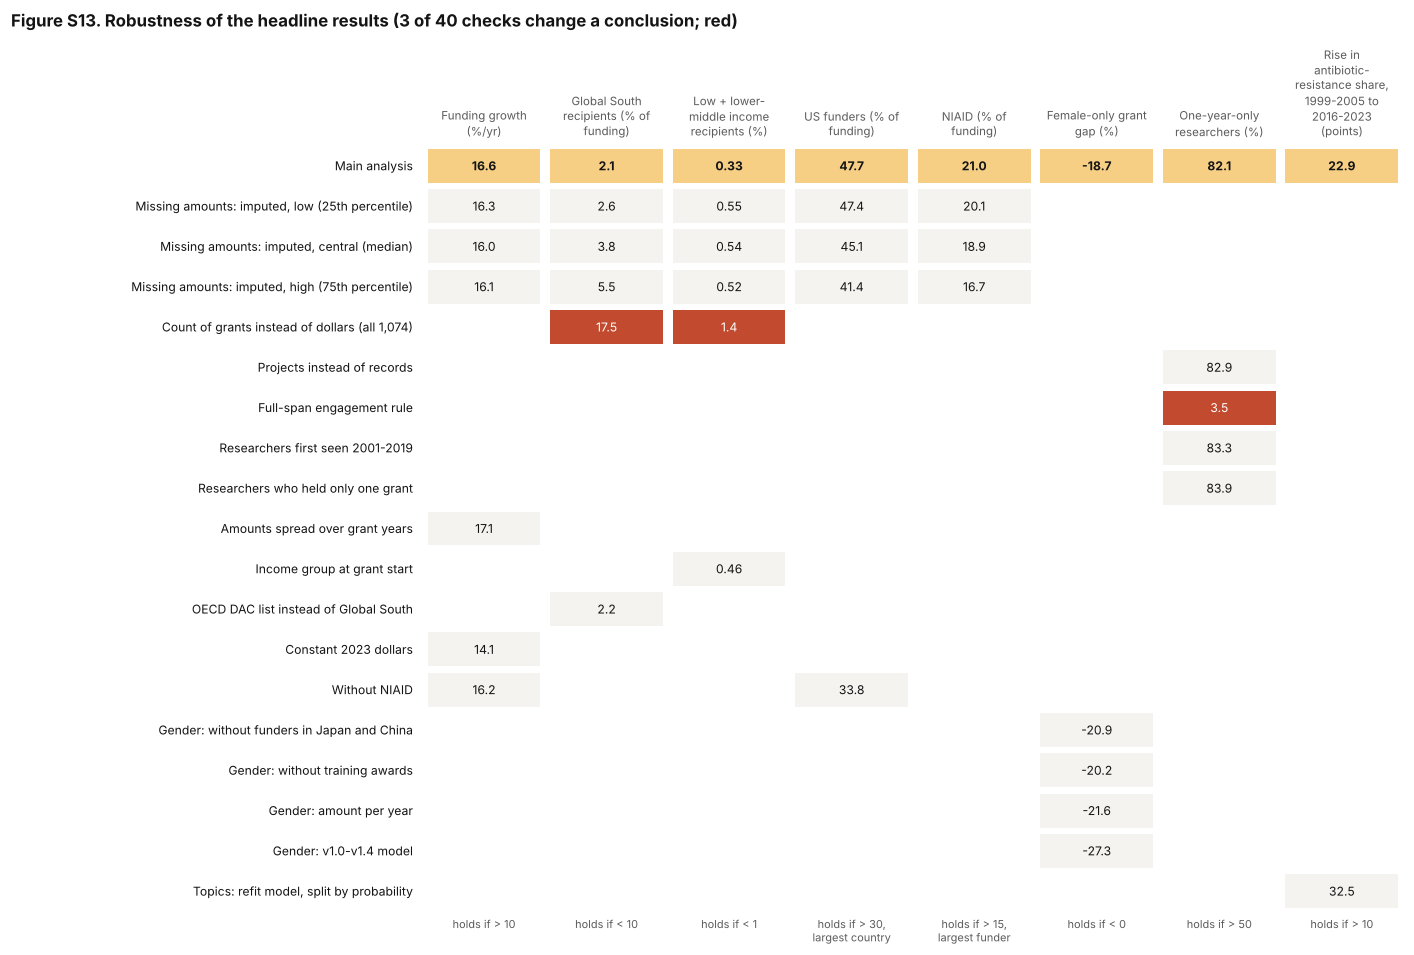

,Funding growth (%/yr),Global South recipients (% of funding),Low + lower-middle income recipients (%),US funders (% of funding),NIAID (% of funding),Female-only grant gap (%),One-year-only researchers (%),"Rise in antibiotic-resistance share, 1999-2005 to 2016-2023 (points)"
Check,,,,,,,,
Main analysis,16.6,2.1,0.33,47.7,21.0,-18.73,82.1,22.9
"Missing amounts: imputed, low (25th percentile)",16.3,2.64,0.55,47.4,20.15,NaN,NaN,NaN
"Missing amounts: imputed, central (median)",16.0,3.8,0.54,45.11,18.9,NaN,NaN,NaN
"Missing amounts: imputed, high (75th percentile)",16.1,5.49,0.52,41.39,16.71,NaN,NaN,NaN
"Count of grants instead of dollars (all 1,074)",NaN,17.5,1.4,NaN,NaN,NaN,NaN,NaN
Projects instead of records,NaN,NaN,NaN,NaN,NaN,NaN,82.9,NaN
Full-span engagement rule,NaN,NaN,NaN,NaN,NaN,NaN,3.5,NaN
Researchers first seen 2001-2019,NaN,NaN,NaN,NaN,NaN,NaN,83.31,NaN
Researchers who held only one grant,NaN,NaN,NaN,NaN,NaN,NaN,83.9,NaN


In [13]:
t3 = pd.read_csv(TAB / "S3_gender_tests.csv", index_col=0)
fmain = t3[(t3.index == "Female only vs Male only") & t3.Model.str.startswith("Main")].iloc[0]
H = ["Funding growth (%/yr)", "Global South recipients (% of funding)", "Low + lower-middle income recipients (%)",
     "US funders (% of funding)", "NIAID (% of funding)", "Female-only grant gap (%)", "One-year-only researchers (%)",
     "Rise in antibiotic-resistance share, 1999-2005 to 2016-2023 (points)"]
eng = pf.engagement_summary(d)
ar = "Antibiotic resistance strategies"
ar_rise_main = s36.loc[ar, "2016-2023, 2024 model (%)"] - s36.loc[ar, "1999-2005, 2024 model (%)"]
ar_rise_split = s36.loc[ar, "2016-2023, split, refit (%)"] - s36.loc[ar, "1999-2005, split, refit (%)"]
NA = [np.nan] * 8
def row(**kw):
    r = NA.copy()
    for j, v in kw.items():
        r[int(j[1:])] = v
    return r
main_row = [key["usd_growth"]["annual_growth_pct"], key["global_south_recipients_pct"], key["lmic_low_recipients_pct"],
            key["us_funders_pct"], key["niaid_share_pct"], fmain["Adjusted difference (%)"],
            float(pd.read_csv(TAB / "S7_engagement_definitions.csv", index_col=0).loc["Transient", "Start year only (%)"]),
            ar_rise_main]
R = {"Main analysis": main_row}
def scen(col):
    s = s33[col]
    return [s["Funding growth 1999-2022 (%/yr)"], s["Recipients in the Global South (%)"],
            s["Recipients in low or lower-middle income countries (%)"], s["Funding from US funders (%)"],
            s["Funding from NIAID (%)"], np.nan, np.nan, np.nan]
for col in s33.columns[1:]:
    R["Missing amounts: " + col.lower()] = scen(col)
R["Count of grants instead of dollars (all 1,074)"] = row(h1=s32.loc["Recipients in the Global South (%)", "All relevant grants"],
    h2=s32.loc["Recipients in low or lower-middle income countries (%)", "All relevant grants"])
R["Projects instead of records"] = row(h6=s34.loc["Transient researchers, start-year rule (%)", "Projects"])
R["Full-span engagement rule"] = row(h6=s34.loc["Transient researchers, full-span rule (%)", "Grant records"])
R["Researchers first seen 2001-2019"] = row(h6=other.iloc[3])
R["Researchers who held only one grant"] = row(h6=eng.attrs["single_grant_share"])
R["Amounts spread over grant years"] = row(h0=other.iloc[0])
R["Income group at grant start"] = row(h2=other.iloc[1])
R["OECD DAC list instead of Global South"] = row(h1=other.iloc[2])
R["Constant 2023 dollars"] = row(h0=key["usd_growth_real_2023"]["annual_growth_pct"])
R["Without NIAID"] = row(h0=key["without_niaid_usd_growth_pct"], h3=key["without_niaid_us_funders_pct"])
for _, r in s35.iloc[1:].iterrows():
    R[f"Gender: {r.name[0].lower() + r.name[1:]}"] = row(h5=r["Female-only vs male-only (%)"])
R["Gender: amount per year"] = row(h5=t3[(t3.index == "Female only vs Male only") & t3.Model.str.startswith("Amount per year")].iloc[0]["Adjusted difference (%)"])
R["Gender: v1.0-v1.4 model"] = row(h5=t3[(t3.index == "Female only vs Male only") & t3.Model.str.startswith("Without")].iloc[0]["Adjusted difference (%)"])
R["Topics: refit model, split by probability"] = row(h7=ar_rise_split)
s37 = pd.DataFrame(R, index=H).T.round(2)
RULES = {H[0]: ("> 10", lambda v: v > 10), H[1]: ("< 10", lambda v: v < 10), H[2]: ("< 1", lambda v: v < 1),
         H[3]: ("> 30, largest country", lambda v: v > 30), H[4]: ("> 15, largest funder", lambda v: v > 15),
         H[5]: ("< 0", lambda v: v < 0), H[6]: ("> 50", lambda v: v > 50), H[7]: ("> 10", lambda v: v > 10)}
holds = s37.apply(lambda col: col.map(lambda v: np.nan if pd.isna(v) else RULES[col.name][1](v)))
s37_out = s37.copy()
s37_out.loc["Conclusion holds if"] = [RULES[h][0] for h in H]
s37_out.index.name = "Check"
s37_out.to_csv(TAB / "S37_robustness_summary.csv")

import textwrap
fig, ax = plt.subplots(figsize=(11.5, 0.36 * len(s37) + 2.2))
ax.set_xlim(0, len(H)); ax.set_ylim(len(s37), 0); ax.axis("off")
for i, (chk, row) in enumerate(s37.iterrows()):
    for j, h in enumerate(H):
        v = row[h]
        if pd.isna(v):
            continue
        ok = holds.loc[chk, h]
        ax.add_patch(plt.Rectangle((j + 0.04, i + 0.08), 0.92, 0.84, fc=(fg.SEQ[1] if i == 0 else ("#f4f3f0" if ok else pf.PALETTE[2])), ec="none"))
        ax.text(j + 0.5, i + 0.5, f"{v:.2f}" if abs(v) < 1 else f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if not ok else pf.INK, fontweight="bold" if i == 0 else "normal")
    ax.text(-0.08, i + 0.5, chk, ha="right", va="center", fontsize=8, color=pf.INK)
for j, h in enumerate(H):
    ax.text(j + 0.5, -0.15, textwrap.fill(h, 17), ha="center", va="bottom", fontsize=7.6, color=pf.INK2, linespacing=1.1)
    ax.text(j + 0.5, len(s37) + 0.15, textwrap.fill("holds if " + RULES[h][0], 16), ha="center", va="top", fontsize=7.2, color=pf.INK2)
n_changed = int((holds == False).sum().sum())
ax.set_title(f"Figure S13. Robustness of the headline results ({n_changed} of {int(holds.notna().sum().sum())} checks change a conclusion; red)",
             loc="left", pad=78, x=-0.42)
fg.save(fig, FIG, "FigS13_robustness"); plt.show()
s37_out

## 13. Key numbers

In [14]:
cen = s33["Imputed, central (median)"]
key.update({
    "relevant_grants_1999_2023": int(len(d) + len(u)),
    "grants_without_amount_1999_2023": int(len(u)),
    "unpriced_training_award_pct": round(float((u.award_type == "Training award").mean() * 100), 1),
    "count_based_global_south_recipients_pct": float(s32.loc["Recipients in the Global South (%)", "All relevant grants"]),
    "count_based_global_south_recipients_priced_pct": float(s32.loc["Recipients in the Global South (%)", "With an amount"]),
    "imputed_global_south_recipients_pct_range": [float(s33.loc["Recipients in the Global South (%)", c]) for c in
                                                  ["Imputed, low (25th percentile)", "Imputed, central (median)", "Imputed, high (75th percentile)"]],
    "imputed_lmic_low_recipients_pct_central": float(cen["Recipients in low or lower-middle income countries (%)"]),
    "female_only_gap_main_pct": round(float(fmain["Adjusted difference (%)"]), 1),
    "female_only_gap_main_ci": [round(float(fmain["95% CI low (%)"]), 1), round(float(fmain["95% CI high (%)"]), 1)],
    "projects": int(len(proj)), "projects_from_multiple_records": int(len(merged)),
    "robustness_checks_changing_a_conclusion": n_changed,
    "researchers_single_grant_pct": float(eng.attrs["single_grant_share"]),
    "antibiotic_resistance_rise_points": {"2024_model": round(float(ar_rise_main), 1), "refit_split": round(float(ar_rise_split), 1)},
})
KN.write_text(json.dumps(key, indent=2))
{k: key[k] for k in list(key)[-15:]}

{'without_niaid_usd_growth_pct': 16.2,
 'relevant_grants_1999_2023': 1074,
 'grants_without_amount_1999_2023': 272,
 'unpriced_training_award_pct': 43.0,
 'count_based_global_south_recipients_pct': 17.5,
 'count_based_global_south_recipients_priced_pct': 11.8,
 'imputed_global_south_recipients_pct_range': [2.64, 3.8, 5.49],
 'imputed_lmic_low_recipients_pct_central': 0.54,
 'female_only_gap_main_pct': -18.7,
 'female_only_gap_main_ci': [-32.3, -2.5],
 'projects': 771,
 'projects_from_multiple_records': 25,
 'robustness_checks_changing_a_conclusion': 3,
 'researchers_single_grant_pct': 83.9,
 'antibiotic_resistance_rise_points': {'2024_model': 22.9,
  'refit_split': 32.5}}